# 🧩 Trabajo Práctico Integrador · Entrega 4: Análisis Exploratorio de Datos (EDA)

* **Institución:** Universidad Tecnológica Nacional (UTN) — Tecnicatura Universitaria en Programación a Distancia
* **Materia:** Introducción al Análisis de Datos (Unidad N° 4 · Semanas 9 y 10)
* **Comisión:** 8
* **Integrantes del Equipo:**
  * **López, Emanuel Gustavo** (Legajo: 101135)
  * **Del Corro, Santino**
* **Número de Entrega:** Entrega N° 4 (Notebook independiente y reproducible)
* **Dataset Asignado:** `hotel booking TPI grupo H.csv` (Grupo H)
* **Variable Objetivo:** `is_canceled` (`0` = Reserva No Cancelada / Efectivizada, `1` = Reserva Cancelada)
* **Recorrido Elegido:** **SQL (DuckDB) + Python (`pandas`, `matplotlib`, `seaborn`)**

---

## 📌 Introducción y Problema de Análisis

En la gestión hotelera moderna, la **cancelación de reservas** constituye uno de los principales desafíos operativos y financieros: distorsiona las proyecciones de ocupación, reduce los ingresos efectivos por habitación disponible y complejiza las políticas de sobreventa (*overbooking*) y fijación de precios.

Dando continuidad al recorrido desarrollado en las Entregas 1, 2 y 3 sobre el dataset asignado a nuestra comisión (`hotel booking TPI grupo H.csv`), este notebook independiente integra:
1. **Primera Parte (Avance de la Semana 9):** Reconocimiento del contexto y unidad de análisis, validación estructural de la tabla mediante **SQL**, selección de variables clave y análisis exploratorio univariado (distribuciones iniciales individuales) acompañado de la formulación de hipótesis exploratorias.
2. **Segunda Parte (Profundización de la Semana 10 - Entrega 4):** Selección de tres preguntas/hipótesis centrales, comparación sistemática entre grupos mediante consultas **SQL** y medidas de resumen (tendencia central, dispersión y proporciones), visualizaciones comparativas en **Python**, identificación de patrones y casos llamativos (anomalías sin eliminación automática), selección justificada de variables candidatas para modelado, conclusiones respaldadas por evidencia y alcances/limitaciones metodológicas.

---
## 🛠️ 0. Preparación Reproducible del Entorno, Carga del Dataset y Continuidad del TPI

Para garantizar que este notebook sea **100% independiente y ejecutable desde el comienzo** (tanto en Google Colab como en un entorno local) sin depender de archivos externos ni celdas previas:
1. Se verifica e instala automáticamente `duckdb` en caso de no encontrarse en el entorno.
2. Se carga el dataset original `hotel booking TPI grupo H.csv` localmente o, si se ejecuta en la nube de Google Colab sin haber subido el archivo manualmente, **se descarga automáticamente desde el repositorio GitHub del equipo**.
3. Se reconstruyen las decisiones de limpieza y variables derivadas justificadas en las Entregas 2 y 3:
   * Imputación de valores faltantes: `children` (1 nulo $\rightarrow 0$), `country` (97 nulos $\rightarrow$ `'Unknown'`), `agent` (3.403 nulos $\rightarrow 0$, reserva sin agente) y `company` (23.580 nulos $\rightarrow 0$, reserva particular sin empresa).
   * Conversión de tipos de datos (`children`, `agent` y `company` a enteros).
   * Creación de variables derivadas fundamentales:
     * `total_stays_nights` = `stays_in_weekend_nights + stays_in_week_nights` (duración total de la estadía en noches).
     * `total_guests` = `adults + children + babies` (cantidad total de huéspedes de la reserva).
4. Se registra la tabla `reservas` en un motor **DuckDB** en memoria para realizar todas las consultas mediante **SQL estándar**.

In [1]:
# 1. Preparación automática de librerías (SQL con DuckDB + Python para entorno y gráficos)
import importlib.util
import subprocess
import sys
from pathlib import Path
from urllib.request import urlretrieve

if importlib.util.find_spec("duckdb") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "duckdb"])

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética general de las visualizaciones
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

# 2. Carga reproducible del dataset original (Local o descarga automática desde GitHub en Colab)
GITHUB_RAW_URL = "https://raw.githubusercontent.com/Emanstor/tpi-iad-comision8/main/hotel%20booking%20TPI%20grupo%20H.csv"
POSSIBLE_PATHS = [
    Path("hotel booking TPI grupo H.csv"),
    Path("sample_data/hotel booking TPI grupo H.csv"),
    Path("hotel booking TPI grupo H (3).csv")
]

data_path = next((p for p in POSSIBLE_PATHS if p.exists()), None)
if data_path is None:
    data_path = Path("hotel booking TPI grupo H.csv")
    print("Descargando dataset original desde el repositorio GitHub del equipo...")
    urlretrieve(GITHUB_RAW_URL, data_path)

df_original = pd.read_csv(data_path)
df = df_original.copy()

# 3. Reconstrucción de preparaciones mínimas y variables derivadas (Continuidad Entregas 2 y 3)
df["children"] = df["children"].fillna(0).astype(int)
df["country"] = df["country"].fillna("Unknown")
df["agent"] = df["agent"].fillna(0).astype(int)
df["company"] = df["company"].fillna(0).astype(int)

# Variables derivadas esenciales
df["total_stays_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["total_guests"] = df["adults"] + df["children"] + df["babies"]

# 4. Conexión a DuckDB y creación de la tabla SQL 'reservas'
con = duckdb.connect(":memory:")
con.register("reservas_df", df)
con.execute("CREATE OR REPLACE TABLE reservas AS SELECT * FROM reservas_df")

print(f"✅ Entorno SQL + Python preparado con éxito.")
print(f"📊 Tabla 'reservas' disponible en DuckDB con {len(df):,} filas y {df.shape[1]} columnas.")

✅ Entorno SQL + Python preparado con éxito.
📊 Tabla 'reservas' disponible en DuckDB con 25,000 filas y 34 columnas.


---
# 📘 PRIMERA PARTE · Avance de la Semana 9: Contexto, Estructura y Distribuciones Iniciales

> **Alcance metodológico de esta primera sección (Semana 9):** Se describe el contexto del dataset, su unidad de análisis, su estructura mediante SQL y el comportamiento **individual (univariado)** de la variable objetivo y de las variables seleccionadas, formulando al cierre las preguntas e hipótesis exploratorias que se contrastarán en la Segunda Parte (Semana 10).

---

## 1. Unidad de Análisis y Definición de la Variable Objetivo (`is_canceled`)

### 1.1. ¿Cuál es la unidad de análisis y qué representa cada fila?
* **Unidad de análisis:** Cada registro (fila) de la tabla `reservas` representa **una reserva hotelera individual** efectuada en un establecimiento (*City Hotel* o *Resort Hotel*), identificada de manera unívoca por el campo `booking_id`.
* **Distinción conceptual importante:** La tabla registra **reservas** y no huéspedes únicos. Un mismo cliente podría haber realizado más de una reserva a lo largo del tiempo (situación reflejada indirectamente por variables como `is_repeated_guest`, `previous_cancellations` y `previous_bookings_not_canceled`).

### 1.2. ¿Qué representa la variable objetivo `is_canceled` y cuáles son sus valores posibles?
* **`is_canceled`** es una variable categórica **binaria (dicotómica)** codificada numéricamente como entero (`BIGINT` / `INTEGER`), que indica el desenlace final de la reserva:
  * **`0` (No Cancelada):** La reserva fue efectivizada normalmente (el huésped realizó el *check-in* y se alojó en el hotel).
  * **`1` (Cancelada):** La reserva fue anulada por el cliente antes del ingreso o concluyó en no presentación (*No-Show*).

Verifiquemos mediante **SQL** que cada fila corresponde efectivamente a un `booking_id` único y que no existen registros duplicados ni valores fuera del dominio `{0, 1}` en `is_canceled`:

In [2]:
# Validación SQL de la unidad de análisis y dominio de la variable objetivo
con.sql("""
SELECT
    COUNT(*) AS total_filas,
    COUNT(DISTINCT booking_id) AS reservas_unicas_booking_id,
    COUNT(*) - COUNT(DISTINCT booking_id) AS filas_duplicadas,
    MIN(is_canceled) AS valor_min_is_canceled,
    MAX(is_canceled) AS valor_max_is_canceled,
    COUNT(*) - COUNT(is_canceled) AS nulos_is_canceled
FROM reservas
""").df()

,total_filas,reservas_unicas_booking_id,filas_duplicadas,valor_min_is_canceled,valor_max_is_canceled,nulos_is_canceled
0,25000,25000,0,0,1,0


**Interpretación breve:** La consulta SQL confirma que el dataset consta exactamente de **25.000 filas** y **25.000 identificadores `booking_id` distintos** (0 duplicados), corroborando que cada fila es una reserva individual. Asimismo, `is_canceled` no presenta valores nulos y toma exclusivamente valores entre `0` y `1`.

---

## 2. Revisión de la Estructura de la Tabla mediante SQL

Inspeccionamos a continuación las 34 columnas de la tabla `reservas` (32 originales + 2 derivadas), sus tipos de datos en SQL y las primeras 5 observaciones del conjunto de datos.

In [3]:
# Estructura de columnas y tipos de datos en DuckDB
con.sql("""
DESCRIBE reservas
""").df()

,column_name,column_type,null,key,default,extra
0,booking_id,VARCHAR,YES,None,None,None
1,hotel,VARCHAR,YES,None,None,None
2,is_canceled,BIGINT,YES,None,None,None
3,lead_time,BIGINT,YES,None,None,None
4,arrival_date_year,BIGINT,YES,None,None,None
5,arrival_date_month,VARCHAR,YES,None,None,None
6,arrival_date_week_number,BIGINT,YES,None,None,None
7,arrival_date_day_of_month,BIGINT,YES,None,None,None
8,arrival_date,VARCHAR,YES,None,None,None
9,stays_in_weekend_nights,BIGINT,YES,None,None,None


In [4]:
# Primeras 5 observaciones de la tabla 'reservas'
con.sql("""
SELECT
    booking_id, hotel, is_canceled, lead_time, arrival_date,
    stays_in_weekend_nights, stays_in_week_nights, total_stays_nights,
    adults, children, babies, total_guests,
    market_segment, distribution_channel, deposit_type, adr, total_of_special_requests
FROM reservas
LIMIT 5
""").df()

,booking_id,hotel,is_canceled,lead_time,arrival_date,stays_in_weekend_nights,stays_in_week_nights,total_stays_nights,adults,children,babies,total_guests,market_segment,distribution_channel,deposit_type,adr,total_of_special_requests
0,HB-024689,Resort Hotel,1,85,2024-08-14,4,10,14,2,1,0,3,Direct,Direct,No Deposit,217.14,2
1,HB-061257,City Hotel,1,77,2024-12-06,0,2,2,2,0,0,2,Online TA,TA/TO,No Deposit,79.20,2
2,HB-100520,City Hotel,0,91,2024-10-23,2,4,6,1,0,0,1,Online TA,TA/TO,No Deposit,132.60,1
3,HB-029150,Resort Hotel,0,0,2024-10-21,0,1,1,2,0,0,2,Online TA,TA/TO,No Deposit,75.00,2
4,HB-095963,City Hotel,0,133,2024-08-21,2,3,5,2,0,0,2,Online TA,TA/TO,No Deposit,70.04,2


**Interpretación breve:** La estructura verificada en SQL muestra 34 campos correctamente tipados: variables identificadoras y categóricas como texto (`VARCHAR`: `booking_id`, `hotel`, `arrival_date_month`, `meal`, `country`, `market_segment`, `distribution_channel`, `deposit_type`, `customer_type`), conteos e indicadores como enteros (`BIGINT`/`INTEGER`: `is_canceled`, `lead_time`, `total_stays_nights`, `total_guests`, `total_of_special_requests`) y la tarifa diaria promedio (`adr`) como punto flotante de doble precisión (`DOUBLE`).

---

## 3. Selección de Variables Relevantes para el Análisis Exploratorio

Para continuar el análisis exploratorio seleccionamos **cinco variables principales** (complementadas por indicadores de depósito y compromiso) que cubren las dimensiones temporal, económica, comercial y operativa de cada reserva:

| Variable | Tipo de Variable | Descripción y Relevancia para el Análisis |
|---|---|---|
| **`lead_time`** | Cuantitativa discreta | Cantidad de días transcurridos entre la fecha en que se realizó la reserva y la fecha prevista de llegada. Mide el horizonte de planificación del cliente. |
| **`adr`** (*Average Daily Rate*) | Cuantitativa continua | Tarifa diaria promedio de la habitación (en unidades monetarias). Permite explorar el nivel de precio asociado a las estadías reservadas. |
| **`total_stays_nights`** | Cuantitativa discreta (Derivada) | Duración total de la estadía reservada (`stays_in_weekend_nights + stays_in_week_nights`). Sintetiza la extensión del viaje. |
| **`hotel`** | Categórica nominal | Tipo de establecimiento hotelero (`City Hotel` urbano vs. `Resort Hotel` vacacional). Refleja perfiles de demanda diferentes. |
| **`market_segment`** (y **`arrival_date_month`**) | Categórica nominal / Temporal | Segmento comercial por el cual ingresó la reserva (`Online TA`, `Offline TA/TO`, `Groups`, `Direct`, `Corporate`, etc.) y mes de arribo previsto (`arrival_date_month`). |

---

## 4. Distribución Inicial de la Variable Objetivo (`is_canceled`)

Obtenemos mediante **SQL** la tabla de frecuencias absolutas y relativas de `is_canceled` y construimos su visualización univariada en **Python**.

In [5]:
# Tabla de frecuencias de la variable objetivo is_canceled mediante SQL
freq_canceled = con.sql("""
SELECT
    is_canceled,
    CASE
        WHEN is_canceled = 0 THEN 'No Cancelada (0)'
        ELSE 'Cancelada (1)'
    END AS estado_reserva,
    COUNT(*) AS cantidad_reservas,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS porcentaje
FROM reservas
GROUP BY is_canceled
ORDER BY is_canceled
""").df()

freq_canceled

,is_canceled,estado_reserva,cantidad_reservas,porcentaje
0,0,No Cancelada (0),15739,62.96
1,1,Cancelada (1),9261,37.04


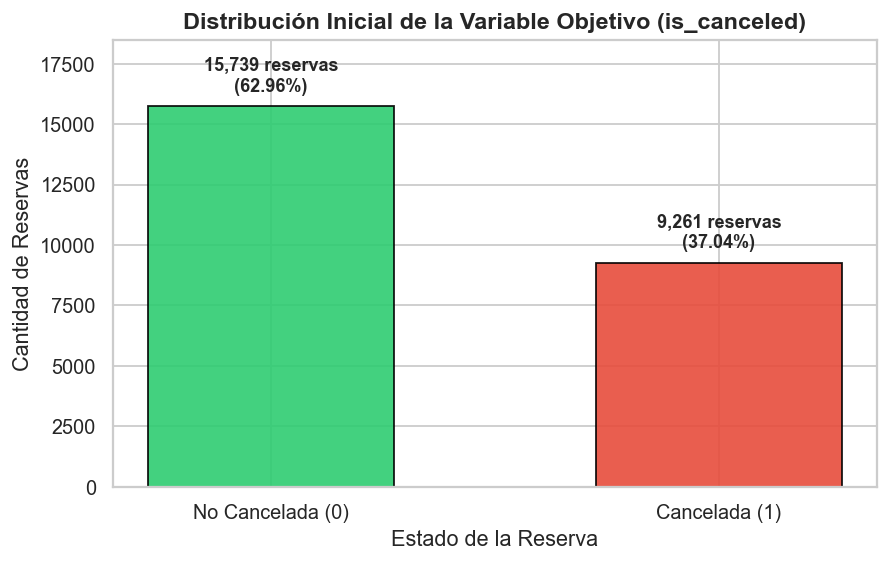

In [6]:
# Visualización simple de la distribución de is_canceled
fig, ax = plt.subplots(figsize=(7, 4.5))
colores = ["#2ecc71", "#e74c3c"]
barras = ax.bar(freq_canceled["estado_reserva"], freq_canceled["cantidad_reservas"], color=colores, width=0.55, edgecolor="black", alpha=0.9)

ax.set_title("Distribución Inicial de la Variable Objetivo (is_canceled)")
ax.set_xlabel("Estado de la Reserva")
ax.set_ylabel("Cantidad de Reservas")
ax.set_ylim(0, 18500)

for barra, pct in zip(barras, freq_canceled["porcentaje"]):
    altura = barra.get_height()
    ax.annotate(
        f"{int(altura):,} reservas\n({pct:.2f}%)",
        xy=(barra.get_x() + barra.get_width() / 2, altura),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center", va="bottom", fontweight="bold", fontsize=10
    )

plt.tight_layout()
plt.show()

**Interpretación descriptiva (Semana 9):**
* Sobre el total de **25.000 reservas**, **15.739 reservas (62,96%)** no fueron canceladas (`is_canceled = 0`), mientras que **9.261 reservas (37,04%)** terminaron en cancelación (`is_canceled = 1`).
* Se observa que más de un tercio de las reservas registradas en el dataset se cancelan, lo que representa una proporción elevada y con suficiente volumen en ambas categorías para realizar comparaciones estadísticas sólidas en la etapa siguiente.

---

## 5. Resúmenes Descriptivos y Distribuciones Individuales de las Variables Seleccionadas (Semana 9)

### 5.1. Variables Cuantitativas (`lead_time`, `adr` y `total_stays_nights`)
Calculamos en **SQL** las medidas de posición (mínimo, cuartiles Q1, mediana Q2, promedio, Q3 y máximo) y de dispersión (desvío estándar) para las tres variables cuantitativas seleccionadas.

In [7]:
# Resumen descriptivo univariado en SQL de las variables cuantitativas seleccionadas
resumen_cuant = con.sql("""
SELECT
    'lead_time (días de anticipación)' AS variable,
    COUNT(lead_time) AS n,
    ROUND(AVG(lead_time), 2) AS media,
    ROUND(STDDEV(lead_time), 2) AS desvio_estandar,
    MIN(lead_time) AS minimo,
    QUANTILE_CONT(lead_time, 0.25) AS q25,
    MEDIAN(lead_time) AS mediana,
    QUANTILE_CONT(lead_time, 0.75) AS q75,
    MAX(lead_time) AS maximo
FROM reservas

UNION ALL

SELECT
    'adr (tarifa diaria promedio)',
    COUNT(adr),
    ROUND(AVG(adr), 2),
    ROUND(STDDEV(adr), 2),
    ROUND(MIN(adr), 2),
    ROUND(QUANTILE_CONT(adr, 0.25), 2),
    ROUND(MEDIAN(adr), 2),
    ROUND(QUANTILE_CONT(adr, 0.75), 2),
    ROUND(MAX(adr), 2)
FROM reservas

UNION ALL

SELECT
    'total_stays_nights (noches totales)',
    COUNT(total_stays_nights),
    ROUND(AVG(total_stays_nights), 2),
    ROUND(STDDEV(total_stays_nights), 2),
    MIN(total_stays_nights),
    QUANTILE_CONT(total_stays_nights, 0.25),
    MEDIAN(total_stays_nights),
    QUANTILE_CONT(total_stays_nights, 0.75),
    MAX(total_stays_nights)
FROM reservas
""").df()

resumen_cuant

,variable,n,media,desvio_estandar,minimo,q25,mediana,q75,maximo
0,lead_time (días de anticipación),25000,104.22,107.32,0.0,18.00,69.0,160.0,629.0
1,adr (tarifa diaria promedio),25000,102.07,58.73,0.0,69.91,95.0,126.0,5400.0
2,total_stays_nights (noches totales),25000,3.43,2.58,0.0,2.00,3.0,4.0,69.0


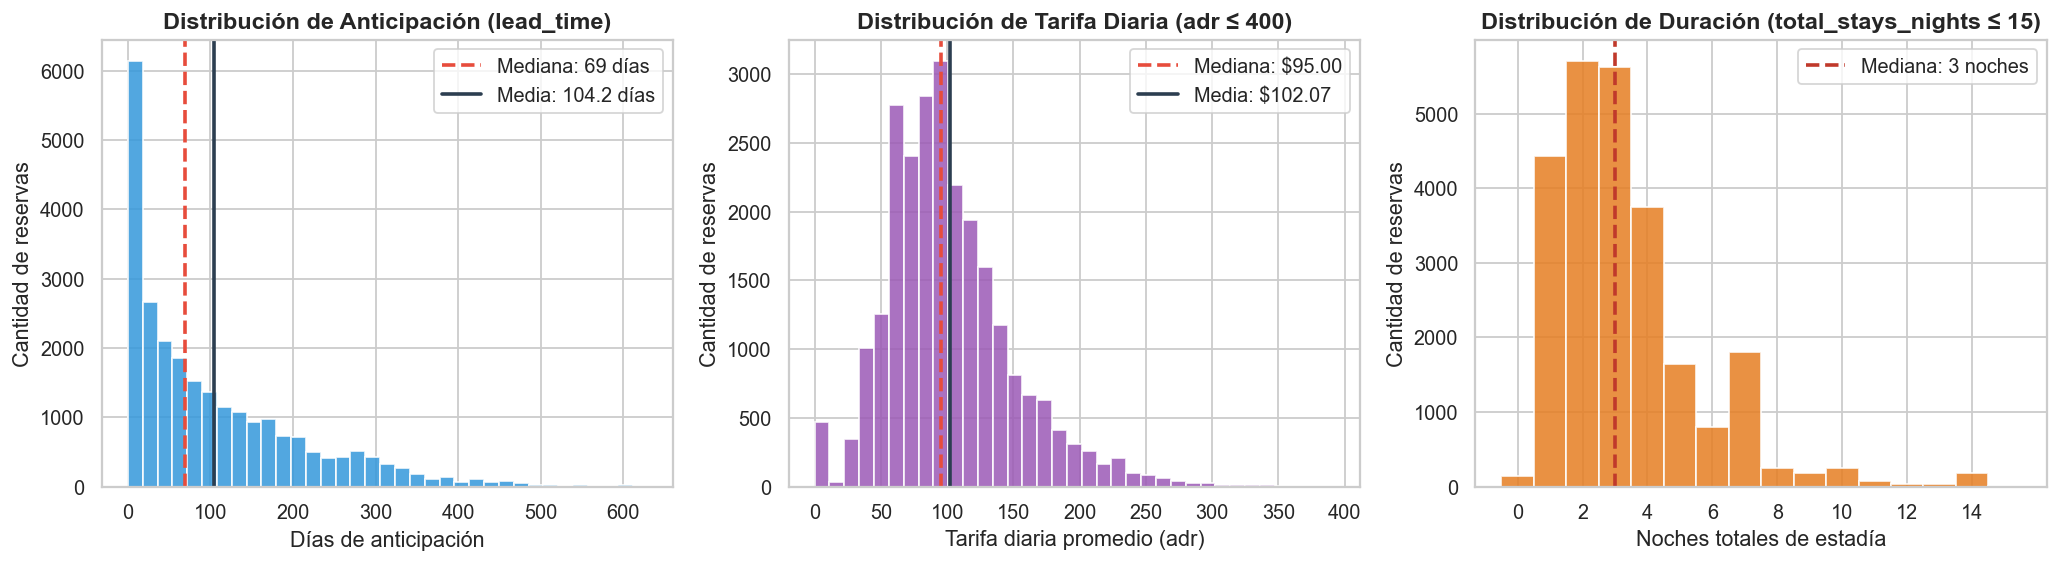

In [8]:
# Visualizaciones iniciales de las distribuciones individuales de las variables cuantitativas
datos_cuant = con.sql("SELECT lead_time, adr, total_stays_nights FROM reservas").df()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Histograma de lead_time
axes[0].hist(datos_cuant["lead_time"], bins=35, color="#3498db", edgecolor="white", alpha=0.85)
axes[0].axvline(datos_cuant["lead_time"].median(), color="#e74c3c", linestyle="--", linewidth=2, label=f"Mediana: {datos_cuant['lead_time'].median():.0f} días")
axes[0].axvline(datos_cuant["lead_time"].mean(), color="#2c3e50", linestyle="-", linewidth=2, label=f"Media: {datos_cuant['lead_time'].mean():.1f} días")
axes[0].set_title("Distribución de Anticipación (lead_time)")
axes[0].set_xlabel("Días de anticipación")
axes[0].set_ylabel("Cantidad de reservas")
axes[0].legend()

# 2. Histograma de adr (acotado visualmente a <= 400 para apreciar la forma central sin el outlier de 5400)
adr_filtrado_vis = datos_cuant[datos_cuant["adr"] <= 400]["adr"]
axes[1].hist(adr_filtrado_vis, bins=35, color="#9b59b6", edgecolor="white", alpha=0.85)
axes[1].axvline(datos_cuant["adr"].median(), color="#e74c3c", linestyle="--", linewidth=2, label=f"Mediana: ${datos_cuant['adr'].median():.2f}")
axes[1].axvline(datos_cuant["adr"].mean(), color="#2c3e50", linestyle="-", linewidth=2, label=f"Media: ${datos_cuant['adr'].mean():.2f}")
axes[1].set_title("Distribución de Tarifa Diaria (adr ≤ 400)")
axes[1].set_xlabel("Tarifa diaria promedio (adr)")
axes[1].set_ylabel("Cantidad de reservas")
axes[1].legend()

# 3. Distribución de total_stays_nights (acotado visualmente a <= 15 noches)
noches_vis = datos_cuant[datos_cuant["total_stays_nights"] <= 15]["total_stays_nights"]
axes[2].hist(noches_vis, bins=range(0, 17), align="left", color="#e67e22", edgecolor="white", alpha=0.85)
axes[2].axvline(datos_cuant["total_stays_nights"].median(), color="#c0392b", linestyle="--", linewidth=2, label=f"Mediana: {datos_cuant['total_stays_nights'].median():.0f} noches")
axes[2].set_title("Distribución de Duración (total_stays_nights ≤ 15)")
axes[2].set_xlabel("Noches totales de estadía")
axes[2].set_ylabel("Cantidad de reservas")
axes[2].set_xticks(range(0, 16, 2))
axes[2].legend()

plt.tight_layout()
plt.show()

**Interpretaciones descriptivas breves de las variables cuantitativas (Semana 9):**
* **`lead_time` (Anticipación):** Presenta una distribución marcadamente **asimétrica hacia la derecha (positiva)**. El 50% central de las reservas se concentra entre **18 días (Q1)** y **160 días (Q3)**, con una **mediana de 69 días** y una **media superior (104,22 días)** traccionada por reservas efectuadas con hasta **629 días** de antelación (desvío estándar de 107,32 días).
* **`adr` (Tarifa diaria promedio):** Su distribución central se ubica entre **\$69,92 (Q1)** y **\$126,00 (Q3)**, con una **mediana de \$95,00** y una **media de \$102,07** (desvío estándar de \$58,73). Se detecta un valor mínimo de **\$0,00** y un valor máximo extremo de **\$5.400,00**, el cual se inspeccionará en la sección de casos llamativos.
* **`total_stays_nights` (Duración de la estadía):** La gran mayoría de las reservas corresponde a estadías cortas, con una **mediana de 3 noches**, un rango intercuartílico muy compacto entre **2 y 4 noches**, y una media de **3,43 noches**, aunque existen casos aislados de larga duración que alcanzan hasta **69 noches** (y registros con `0` noches).

---

### 5.2. Variables Categóricas y Temporales (`hotel`, `market_segment` y `arrival_date_month`)
Obtenemos mediante **SQL** las tablas de frecuencias de tipo de hotel, segmento de mercado y mes de llegada, y graficamos sus distribuciones individuales.

In [9]:
# Tabla de frecuencias SQL: Tipo de Hotel (hotel)
freq_hotel = con.sql("""
SELECT
    hotel,
    COUNT(*) AS cantidad,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS porcentaje
FROM reservas
GROUP BY hotel
ORDER BY cantidad DESC
""").df()

freq_hotel

,hotel,cantidad,porcentaje
0,City Hotel,16610,66.44
1,Resort Hotel,8390,33.56


In [10]:
# Tabla de frecuencias SQL: Segmento de Mercado (market_segment)
freq_segment = con.sql("""
SELECT
    market_segment,
    COUNT(*) AS cantidad,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS porcentaje
FROM reservas
GROUP BY market_segment
ORDER BY cantidad DESC
""").df()

freq_segment

,market_segment,cantidad,porcentaje
0,Online TA,11835,47.34
1,Offline TA/TO,5080,20.32
2,Groups,4111,16.44
3,Direct,2693,10.77
4,Corporate,1062,4.25
5,Complementary,158,0.63
6,Aviation,60,0.24
7,Undefined,1,0.00


In [11]:
# Tabla de frecuencias SQL: Mes de arribo (arrival_date_month) ordenado cronológicamente
freq_month = con.sql("""
SELECT
    arrival_date_month AS mes_arribo,
    COUNT(*) AS cantidad,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS porcentaje
FROM reservas
GROUP BY arrival_date_month
ORDER BY CASE arrival_date_month
    WHEN 'January' THEN 1 WHEN 'February' THEN 2 WHEN 'March' THEN 3
    WHEN 'April' THEN 4 WHEN 'May' THEN 5 WHEN 'June' THEN 6
    WHEN 'July' THEN 7 WHEN 'August' THEN 8 WHEN 'September' THEN 9
    WHEN 'October' THEN 10 WHEN 'November' THEN 11 WHEN 'December' THEN 12
END
""").df()

freq_month

,mes_arribo,cantidad,porcentaje
0,January,1242,4.97
1,February,1690,6.76
2,March,2051,8.20
3,April,2321,9.28
4,May,2469,9.88
5,June,2290,9.16
6,July,2651,10.60
7,August,2906,11.62
8,September,2201,8.80
9,October,2336,9.34


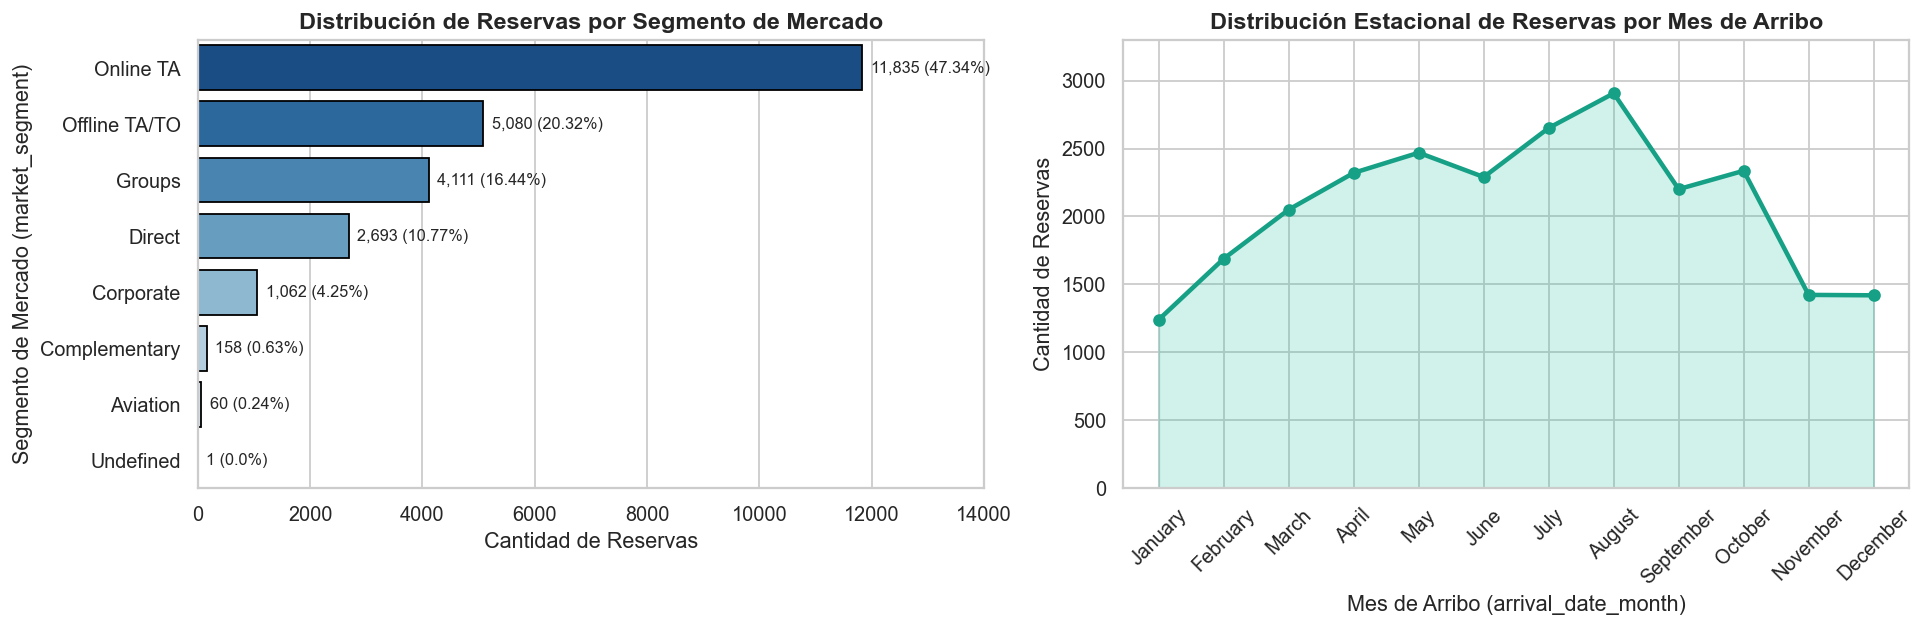

In [12]:
# Visualizaciones iniciales de las variables categóricas y temporales (Semana 9)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico 1: Distribución por Segmento de Mercado
sns.barplot(
    data=freq_segment,
    x="cantidad",
    y="market_segment",
    hue="market_segment",
    palette="Blues_r",
    legend=False,
    ax=axes[0],
    edgecolor="black"
)
axes[0].set_title("Distribución de Reservas por Segmento de Mercado")
axes[0].set_xlabel("Cantidad de Reservas")
axes[0].set_ylabel("Segmento de Mercado (market_segment)")
for i, (cant, pct) in enumerate(zip(freq_segment["cantidad"], freq_segment["porcentaje"])):
    axes[0].text(cant + 150, i, f"{cant:,} ({pct}%)", va="center", fontsize=9)
axes[0].set_xlim(0, 14000)

# Gráfico 2: Distribución por Mes de Arribo
axes[1].plot(freq_month["mes_arribo"], freq_month["cantidad"], marker="o", color="#16a085", linewidth=2.5)
axes[1].fill_between(range(len(freq_month)), freq_month["cantidad"], color="#1abc9c", alpha=0.2)
axes[1].set_title("Distribución Estacional de Reservas por Mes de Arribo")
axes[1].set_xlabel("Mes de Arribo (arrival_date_month)")
axes[1].set_ylabel("Cantidad de Reservas")
axes[1].tick_params(axis="x", rotation=45)
axes[1].set_ylim(0, 3300)

plt.tight_layout()
plt.show()

**Interpretaciones descriptivas breves de las variables categóricas y temporales (Semana 9):**
* **`hotel`:** Exactamente dos tercios de las observaciones (**16.610 reservas; 66,44%**) corresponden al **`City Hotel`**, mientras que el tercio restante (**8.390 reservas; 33,56%**) pertenece al **`Resort Hotel`**.
* **`market_segment`:** Casi la mitad de las reservas ingresan a través de agencias de viaje en línea (**`Online TA`: 11.835 casos; 47,34%**), seguidas por agencias/operadores tradicionales (**`Offline TA/TO`: 5.080 casos; 20,32%**), contingentes grupales (**`Groups`: 4.111 casos; 16,44%**) y reservas directas (**`Direct`: 2.693 casos; 10,77%**). Los segmentos `Corporate` (4,25%), `Complementary` (0,63%), `Aviation` (0,24%) y `Undefined` (1 solo caso) tienen una participación minoritaria.
* **`arrival_date_month`:** Se aprecia una marcada estacionalidad en el volumen de arribos, alcanzando su pico durante el verano boreal: **agosto (2.906 reservas; 11,62%)** y **julio (2.651 reservas; 10,60%)**, frente a los mínimos registrados en **enero (1.242 reservas; 4,97%)**, **diciembre (5,68%)** y **noviembre (5,69%)**.

---

## 6. Formulación de Preguntas e Hipótesis Exploratorias (Cierre de la Semana 9)

A partir del reconocimiento inicial de las distribuciones individuales, dejamos planteadas las siguientes **cuatro preguntas/hipótesis exploratorias** para profundizar mediante comparaciones entre grupos en la **Semana 10**:

1. **Hipótesis sobre la anticipación (`lead_time`):** *¿Las reservas que se realizan con mayor cantidad de días de anticipación presentan una propensión más alta a cancelarse en comparación con aquellas efectuadas próximas a la fecha de ingreso?*
2. **Hipótesis sobre el perfil comercial (`hotel` y `market_segment`):** *¿Existen diferencias significativas en la tasa de cancelación entre el `City Hotel` y el `Resort Hotel`, y entre los distintos segmentos de mercado (`Online TA`, `Groups`, `Direct`, `Corporate`)?*
3. **Hipótesis sobre estadía, precio y compromiso del cliente (`total_stays_nights`, `adr`, `deposit_type` y `total_of_special_requests`):** *¿Presentan las reservas canceladas y no canceladas comportamientos distintos en la duración de la estadía o en la tarifa diaria promedio, y cómo varían las cancelaciones según el tipo de depósito, el historial de cancelaciones previas o la cantidad de pedidos especiales?*
4. **Hipótesis sobre estacionalidad (`arrival_date_month`):** *¿Varía la proporción de cancelaciones según el mes o la temporada del año en que se concentra la mayor demanda?*

---
# 📗 SEGUNDA PARTE · Entrega 4 (Semana 10): Comparación de Grupos, Patrones y Selección de Variables

## 1. Revisión del Avance de la Semana 9 y Selección de Tres Preguntas Exploratorias

Tras verificar en la Primera Parte que:
* La **unidad de análisis** es cada reserva individual (`25.000` registros únicos sin duplicados),
* La **variable objetivo** `is_canceled` presenta un balance de **62,96% de reservas efectivizadas** (`15.739`) y **37,04% de canceladas** (`9.261`),
* Variables como `lead_time` y `adr` exhiben fuerte asimetría positiva (por lo cual es indispensable acompañar la **media** y el **desvío estándar** con la **mediana** y el **rango intercuartílico**), y
* Los segmentos comerciales tienen tamaños de grupo muy dispares (desde `11.835` en `Online TA` hasta `1` en `Undefined`),

seleccionamos y reformulamos con precisión **tres preguntas/hipótesis exploratorias** para contrastar mediante **SQL + Python**:

> ### 🎯Las Tres Preguntas / Hipótesis Seleccionadas:
> * **Pregunta Exploratoria 1 (Anticipación de la reserva):** *¿En qué medida difiere la distribución de los días de anticipación (`lead_time`) entre las reservas canceladas y las no canceladas, y cómo evoluciona la tasa de cancelación a través de los distintos tramos de anticipación?*
> * **Pregunta Exploratoria 2 (Tipo de hotel y Segmento de mercado):** *¿Qué diferencias existen en la proporción de cancelaciones según el tipo de hotel (`hotel`) y el segmento de mercado (`market_segment`), tanto de manera individual como al cruzar ambas dimensiones comerciales?*
> * **Pregunta Exploratoria 3 (Duración de estadía, Tarifa diaria y Condiciones de compromiso del huésped):** *¿Presentan la duración de la estadía (`total_stays_nights`) y la tarifa diaria (`adr`) diferencias relevantes entre reservas canceladas y efectivizadas, y cómo se asocian el tipo de depósito (`deposit_type`), las cancelaciones previas (`previous_cancellations`) y los pedidos especiales (`total_of_special_requests`) con el comportamiento de cancelación?*

---

## 2. Desarrollo de la Pregunta Exploratoria 1: Anticipación de la Reserva (`lead_time`) vs. Cancelación

### 2.1. Comparación mediante SQL y Resúmenes Descriptivos
Construimos dos consultas SQL complementarias:
1. Una comparación directa de medidas de resumen (cantidad de casos `n`, media, desvío estándar, cuartiles Q1, mediana Q2, Q3, rango intercuartílico RIC y máximo) de `lead_time` agrupando por `is_canceled`.
2. Una segmentación de `lead_time` en **5 tramos de anticipación** para observar cómo varía la proporción de cancelaciones desde reservas de último momento (`0 a 7 días`) hasta reservas de muy largo plazo (`> 180 días`).

In [13]:
# Consulta SQL 1A: Comparación estadística de lead_time entre reservas No Canceladas (0) y Canceladas (1)
comp_lead_time = con.sql("""
SELECT
    is_canceled,
    CASE WHEN is_canceled = 0 THEN 'No Cancelada (0)' ELSE 'Cancelada (1)' END AS estado_reserva,
    COUNT(*) AS n_casos,
    ROUND(AVG(lead_time), 2) AS media_dias,
    ROUND(STDDEV(lead_time), 2) AS desvio_estandar,
    MIN(lead_time) AS min_dias,
    QUANTILE_CONT(lead_time, 0.25) AS q25_dias,
    MEDIAN(lead_time) AS mediana_dias,
    QUANTILE_CONT(lead_time, 0.75) AS q75_dias,
    QUANTILE_CONT(lead_time, 0.75) - QUANTILE_CONT(lead_time, 0.25) AS ric_dias,
    MAX(lead_time) AS max_dias
FROM reservas
GROUP BY is_canceled
ORDER BY is_canceled
""").df()

comp_lead_time

,is_canceled,estado_reserva,n_casos,media_dias,desvio_estandar,min_dias,q25_dias,mediana_dias,q75_dias,ric_dias,max_dias
0,0,No Cancelada (0),15739,80.28,91.85,0,8.0,45.0,124.0,116.0,542
1,1,Cancelada (1),9261,144.89,118.86,0,49.0,112.0,213.0,164.0,629


In [14]:
# Consulta SQL 1B: Tasa de cancelación según tramos de anticipación (lead_time)
tramos_lead_time = con.sql("""
SELECT
    CASE
        WHEN lead_time <= 7 THEN '1. Corta (0 a 7 días)'
        WHEN lead_time <= 30 THEN '2. Media-Corta (8 a 30 días)'
        WHEN lead_time <= 90 THEN '3. Media (31 a 90 días)'
        WHEN lead_time <= 180 THEN '4. Larga (91 a 180 días)'
        ELSE '5. Muy Larga (> 180 días)'
    END AS tramo_anticipacion,
    COUNT(*) AS total_reservas,
    SUM(is_canceled) AS reservas_canceladas,
    COUNT(*) - SUM(is_canceled) AS reservas_efectivizadas,
    ROUND(AVG(is_canceled) * 100.0, 2) AS tasa_cancelacion_pct,
    ROUND(AVG(adr), 2) AS adr_promedio
FROM reservas
GROUP BY tramo_anticipacion
ORDER BY tramo_anticipacion
""").df()

tramos_lead_time

,tramo_anticipacion,total_reservas,reservas_canceladas,reservas_efectivizadas,tasa_cancelacion_pct,adr_promedio
0,1. Corta (0 a 7 días),4180,397.0,3783.0,9.50,89.39
1,2. Media-Corta (8 a 30 días),3891,1073.0,2818.0,27.58,107.78
2,3. Media (31 a 90 días),6272,2374.0,3898.0,37.85,108.05
3,4. Larga (91 a 180 días),5485,2522.0,2963.0,45.98,109.77
4,5. Muy Larga (> 180 días),5172,2895.0,2277.0,55.97,92.59


### 2.2. Visualizaciones Exploratorias (Pregunta 1)
Representamos en **Python** tanto la comparación de distribuciones completas mediante un diagrama de caja (*boxplot*) como la progresión escalonada de la tasa de cancelación por tramo de anticipación.

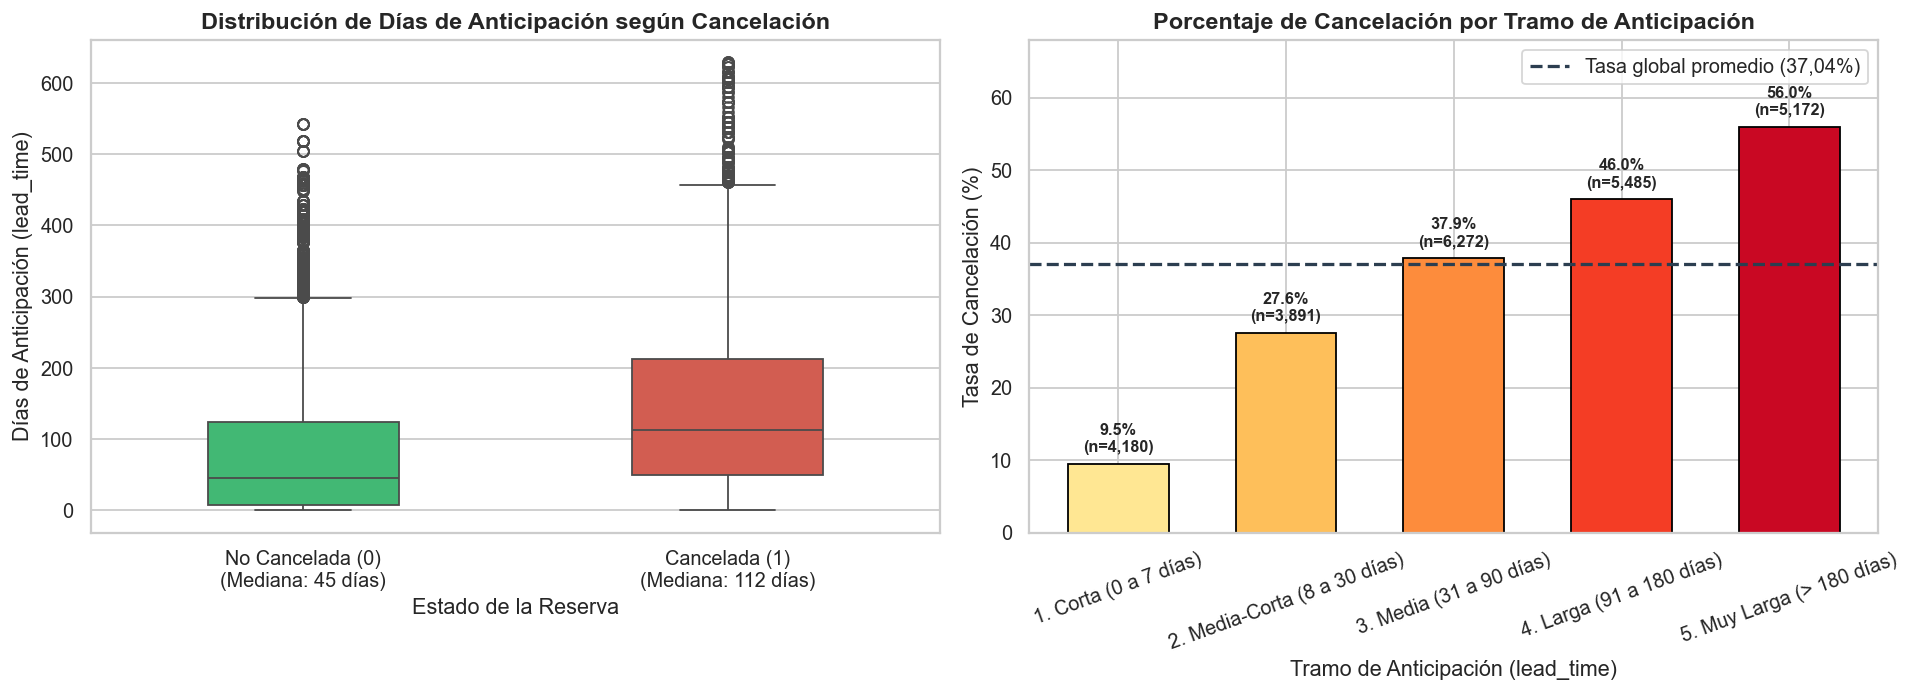

In [15]:
# Visualización Comparativa 1: Boxplot de lead_time por estado + Evolución por tramos de anticipación
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Panel izquierdo: Boxplot comparativo
sns.boxplot(
    data=df,
    x="is_canceled",
    y="lead_time",
    hue="is_canceled",
    palette=["#2ecc71", "#e74c3c"],
    legend=False,
    width=0.45,
    ax=axes[0]
)
axes[0].set_title("Distribución de Días de Anticipación según Cancelación")
axes[0].set_xlabel("Estado de la Reserva")
axes[0].set_ylabel("Días de Anticipación (lead_time)")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["No Cancelada (0)\n(Mediana: 45 días)", "Cancelada (1)\n(Mediana: 112 días)"])

# Panel derecho: Tasa de cancelación por tramo de anticipación
barras_tramo = axes[1].bar(
    tramos_lead_time["tramo_anticipacion"],
    tramos_lead_time["tasa_cancelacion_pct"],
    color=sns.color_palette("YlOrRd", len(tramos_lead_time)),
    edgecolor="black",
    width=0.6
)
axes[1].axhline(37.04, color="#2c3e50", linestyle="--", linewidth=1.8, label="Tasa global promedio (37,04%)")
axes[1].set_title("Porcentaje de Cancelación por Tramo de Anticipación")
axes[1].set_xlabel("Tramo de Anticipación (lead_time)")
axes[1].set_ylabel("Tasa de Cancelación (%)")
axes[1].set_ylim(0, 68)
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend()

for barra, n_tot in zip(barras_tramo, tramos_lead_time["total_reservas"]):
    h = barra.get_height()
    axes[1].annotate(
        f"{h:.1f}%\n(n={n_tot:,})",
        xy=(barra.get_x() + barra.get_width() / 2, h),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center", va="bottom", fontsize=9, fontweight="bold"
    )

plt.tight_layout()
plt.show()

### 2.3. Interpretación de la Pregunta Exploratoria 1

* **📊 Resultado observado (lo que muestran las consultas y los gráficos):**
  1. Las reservas **no canceladas (`n = 15.739`)** tienen una anticipación promedio de **80,28 días** ($DE = 91,85$) y una **mediana de 45 días** ($Q_1 = 8$, $Q_3 = 124$, $RIC = 116$ días). En cambio, las reservas **canceladas (`n = 9.261`)** alcanzan una media de **144,89 días** ($DE = 118,86$) y una **mediana de 112 días** ($Q_1 = 49$, $Q_3 = 213$, $RIC = 164$ días), es decir, su mediana es **más del doble (+67 días)** que la del grupo efectivizado.
  2. Al agrupar por tramos en SQL, la tasa de cancelación crece de manera estrictamente monótona en todos los intervalos (todos con más de 3.800 observaciones): pasa de apenas **9,50%** en reservas de corta anticipación (`0 a 7 días`), a **27,58%** (`8 a 30 días`), **37,85%** (`31 a 90 días`), **45,98%** (`91 a 180 días`) y llega al **55,97%** cuando la anticipación supera los **180 días**.
* **💡 Interpretación analítica (con prudencia metodológica):**
  * Existe una asociación positiva muy marcada entre el horizonte temporal de reserva y la ocurrencia de cancelación. Desde la lógica del negocio hotelero, cuanto mayor es el tiempo entre la compra y el viaje, mayor es la exposición del huésped a cambios de planes, imprevistos laborales o hallazgo de ofertas alternativas.
  * **Límite de interpretación:** Esta fuerte asociación **no implica causalidad pura aislada**, ya que las reservas realizadas con más de 180 días suelen estar vinculadas también a contingentes grupales (`Groups`) o bloqueos de operadores turísticos, cuya modalidad de contratación influye simultáneamente en el resultado.

---

## 3. Desarrollo de la Pregunta Exploratoria 2: Tipo de Hotel (`hotel`) y Segmento de Mercado (`market_segment`)

### 3.1. Comparación mediante SQL y Resúmenes Descriptivos
Realizamos tres consultas SQL para evaluar cómo se distribuyen las cancelaciones según la estructura comercial:
1. Comparación por tipo de establecimiento (`City Hotel` vs. `Resort Hotel`).
2. Comparación por segmento de mercado (`market_segment`), incorporando el tamaño de cada grupo (`n`), la tasa de cancelación, la anticipación promedio y la tarifa media.
3. Comparación bivariada cruzada (`hotel` $\times$ `market_segment`) para los segmentos representativos ($n \ge 50$).

In [16]:
# Consulta SQL 2A: Comparación entre City Hotel y Resort Hotel
comp_hotel = con.sql("""
SELECT
    hotel,
    COUNT(*) AS total_reservas,
    SUM(is_canceled) AS canceladas,
    COUNT(*) - SUM(is_canceled) AS no_canceladas,
    ROUND(AVG(is_canceled) * 100.0, 2) AS tasa_cancelacion_pct,
    ROUND(AVG(lead_time), 2) AS lead_time_medio,
    MEDIAN(lead_time) AS lead_time_mediana,
    ROUND(AVG(adr), 2) AS adr_medio,
    ROUND(AVG(total_stays_nights), 2) AS noches_promedio
FROM reservas
GROUP BY hotel
ORDER BY tasa_cancelacion_pct DESC
""").df()

comp_hotel

,hotel,total_reservas,canceladas,no_canceladas,tasa_cancelacion_pct,lead_time_medio,lead_time_mediana,adr_medio,noches_promedio
0,City Hotel,16610,6930.0,9680.0,41.72,110.20,73.0,105.94,2.98
1,Resort Hotel,8390,2331.0,6059.0,27.78,92.37,57.5,94.40,4.32


In [17]:
# Consulta SQL 2B: Comparación por Segmento de Mercado (market_segment)
comp_segment = con.sql("""
SELECT
    market_segment,
    COUNT(*) AS total_reservas,
    SUM(is_canceled) AS canceladas,
    COUNT(*) - SUM(is_canceled) AS no_canceladas,
    ROUND(AVG(is_canceled) * 100.0, 2) AS tasa_cancelacion_pct,
    ROUND(AVG(lead_time), 1) AS lead_time_medio,
    MEDIAN(lead_time) AS lead_time_mediana,
    ROUND(AVG(adr), 2) AS adr_medio
FROM reservas
GROUP BY market_segment
ORDER BY total_reservas DESC
""").df()

comp_segment

,market_segment,total_reservas,canceladas,no_canceladas,tasa_cancelacion_pct,lead_time_medio,lead_time_mediana,adr_medio
0,Online TA,11835,4321.0,7514.0,36.51,83.3,58.0,117.55
1,Offline TA/TO,5080,1781.0,3299.0,35.06,135.9,111.0,88.45
2,Groups,4111,2504.0,1607.0,60.91,187.0,157.0,78.87
3,Direct,2693,415.0,2278.0,15.41,50.6,16.0,114.59
4,Corporate,1062,202.0,860.0,19.02,20.5,7.0,67.72
5,Complementary,158,21.0,137.0,13.29,14.8,3.0,1.72
6,Aviation,60,16.0,44.0,26.67,4.2,3.0,102.26
7,Undefined,1,1.0,0.0,100.00,2.0,2.0,12.00


In [18]:
# Consulta SQL 2C: Cruce simultáneo Tipo de Hotel x Segmento de Mercado (para grupos con n >= 50)
cruce_hotel_segment = con.sql("""
SELECT
    hotel,
    market_segment,
    COUNT(*) AS n_reservas,
    SUM(is_canceled) AS canceladas,
    ROUND(AVG(is_canceled) * 100.0, 2) AS tasa_cancelacion_pct,
    ROUND(AVG(lead_time), 1) AS lead_time_medio,
    ROUND(AVG(adr), 2) AS adr_medio
FROM reservas
GROUP BY hotel, market_segment
HAVING COUNT(*) >= 50
ORDER BY hotel, tasa_cancelacion_pct DESC
""").df()

cruce_hotel_segment

,hotel,market_segment,n_reservas,canceladas,tasa_cancelacion_pct,lead_time_medio,adr_medio
0,City Hotel,Groups,2916,1984.0,68.04,194.5,84.57
1,City Hotel,Offline TA/TO,3505,1549.0,44.19,143.6,94.94
2,City Hotel,Online TA,8128,3013.0,37.07,83.2,119.23
3,City Hotel,Aviation,60,16.0,26.67,4.2,102.26
4,City Hotel,Corporate,571,124.0,21.72,25.4,82.40
5,City Hotel,Direct,1309,230.0,17.57,51.3,120.60
6,City Hotel,Complementary,120,13.0,10.83,11.4,1.18
7,Resort Hotel,Groups,1195,520.0,43.51,168.6,64.98
8,Resort Hotel,Online TA,3707,1308.0,35.28,83.5,113.85
9,Resort Hotel,Corporate,491,78.0,15.89,14.8,50.65


### 3.2. Visualizaciones Exploratorias (Pregunta 2)
Construimos un panel doble en **Python** que muestra: (a) la tasa de cancelación y tamaño de muestra por segmento de mercado, y (b) la comparación cruzada de tasas de cancelación entre `City Hotel` y `Resort Hotel` dentro de cada segmento comercial.

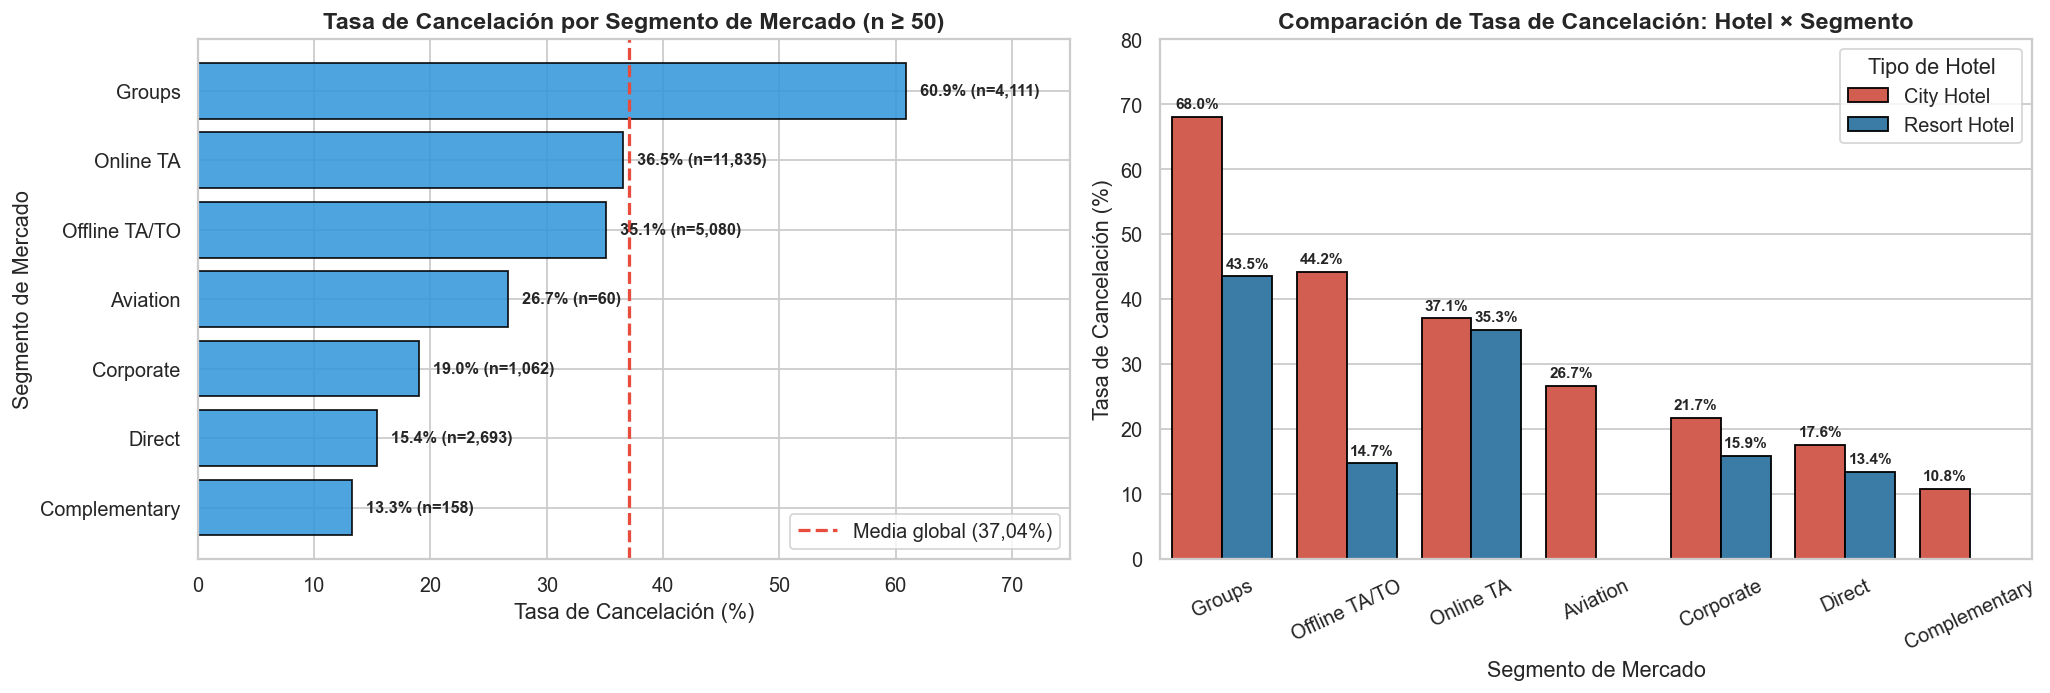

In [19]:
# Visualización Comparativa 2: Tasa de cancelación por Segmento y Cruce con Tipo de Hotel
seg_principales = comp_segment[comp_segment["total_reservas"] >= 50].sort_values("tasa_cancelacion_pct", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Panel 1: Barras horizontales de tasa de cancelación por market_segment
barras_seg = axes[0].barh(
    seg_principales["market_segment"],
    seg_principales["tasa_cancelacion_pct"],
    color="#3498db",
    edgecolor="black",
    alpha=0.88
)
axes[0].axvline(37.04, color="#e74c3c", linestyle="--", linewidth=1.8, label="Media global (37,04%)")
axes[0].set_title("Tasa de Cancelación por Segmento de Mercado (n ≥ 50)")
axes[0].set_xlabel("Tasa de Cancelación (%)")
axes[0].set_ylabel("Segmento de Mercado")
axes[0].set_xlim(0, 75)
axes[0].legend(loc="lower right")

for barra, n_val in zip(barras_seg, seg_principales["total_reservas"]):
    w = barra.get_width()
    axes[0].text(w + 1.2, barra.get_y() + barra.get_height()/2, f"{w:.1f}% (n={n_val:,})", va="center", fontsize=9, fontweight="bold")

# Panel 2: Gráfico de barras agrupadas Hotel x Segmento de Mercado
sns.barplot(
    data=cruce_hotel_segment,
    x="market_segment",
    y="tasa_cancelacion_pct",
    hue="hotel",
    palette=["#e74c3c", "#2980b9"],
    edgecolor="black",
    ax=axes[1]
)
axes[1].set_title("Comparación de Tasa de Cancelación: Hotel × Segmento")
axes[1].set_xlabel("Segmento de Mercado")
axes[1].set_ylabel("Tasa de Cancelación (%)")
axes[1].set_ylim(0, 80)
axes[1].tick_params(axis="x", rotation=25)
axes[1].legend(title="Tipo de Hotel")

for p in axes[1].patches:
    h = p.get_height()
    if h > 0:
        axes[1].annotate(
            f"{h:.1f}%",
            (p.get_x() + p.get_width() / 2., h),
            ha="center", va="bottom", fontsize=8.5, fontweight="bold", xytext=(0, 3), textcoords="offset points"
        )

plt.tight_layout()
plt.show()

### 3.3. Interpretación de la Pregunta Exploratoria 2

* **📊 Resultado observado (lo que muestran las consultas y los gráficos):**
  1. **Por tipo de hotel:** El **`City Hotel`** presenta una tasa de cancelación del **41,72%** (`6.930` canceladas sobre `16.610` reservas), superando en **13,94 puntos porcentuales** al **`Resort Hotel`**, cuya tasa es del **27,78%** (`2.331` canceladas sobre `8.390` reservas). Además, el `Resort Hotel` exhibe estadías más largas en promedio (`4,31` noches vs. `2,98` noches en el `City Hotel`).
  2. **Por segmento de mercado:** El segmento **`Groups`** lidera ampliamente las cancelaciones con un **60,91%** (`2.504` de `4.111` reservas), seguido por **`Online TA`** (**36,51%**, `n = 11.835`) y **`Offline TA/TO`** (**35,06%**, `n = 5.080`). En el extremo opuesto, las reservas directas (**`Direct`**: **15,41%**, `n = 2.693`), corporativas (**`Corporate`**: **19,02%**, `n = 1.062`) y de cortesía (**`Complementary`**: **13,29%**, `n = 158`) registran las tasas más bajas. (El segmento `Undefined` posee $n = 1$ sola observación, por lo que carece de representatividad estadística).
  3. **Interacción `hotel` $\times$ `market_segment`:** Dentro de *todos* los segmentos principales, el `City Hotel` sufre mayor tasa de cancelación que el `Resort Hotel`. Los contrastes más agudos se dan en **`Groups`** (**68,04%** en `City Hotel` vs. **43,51%** en `Resort Hotel`) y en **`Offline TA/TO`** (**44,19%** en `City Hotel` vs. apenas **14,73%** en `Resort Hotel`).
* **💡 Interpretación analítica (con prudencia metodológica):**
  * El canal comercial y el tipo de establecimiento segmentan claramente el riesgo de cancelación. Las reservas directas (`Direct`) y corporativas (`Corporate`) reflejan clientes con planes definidos y menor intermediación, mientras que las agencias online (`Online TA`) suelen ofrecer facilidades de cancelación gratuita con un clic y los contingentes (`Groups`) suelen bloquear cupos preventivos con alta anticipación (`lead_time` medio de 187 días).
  * Nuevamente, se observa cómo las variables interactúan entre sí: el elevado porcentaje de cancelación en `Groups` coincide con su altísimo `lead_time` promedio (`194,5` días en `City Hotel`), lo que refuerza la necesidad de considerar ambas variables conjuntamente en etapas futuras de modelado.

---

## 4. Desarrollo de la Pregunta Exploratoria 3: Estadía (`total_stays_nights`), Tarifa (`adr`) y Compromiso del Huésped (`deposit_type`, `previous_cancellations`, `total_of_special_requests`)

### 4.1. Comparación mediante SQL y Resúmenes Descriptivos
Analizamos mediante tres consultas SQL si las variables de duración/precio y las variables de compromiso contractual y operativo permiten diferenciar a los clientes que cancelan de los que efectivizan su estadía.

In [20]:
# Consulta SQL 3A: Comparación de duración de estadía (total_stays_nights) y tarifa diaria (adr) según is_canceled
comp_estadia_adr = con.sql("""
SELECT
    is_canceled,
    CASE WHEN is_canceled = 0 THEN 'No Cancelada (0)' ELSE 'Cancelada (1)' END AS estado_reserva,
    COUNT(*) AS n_casos,
    ROUND(AVG(total_stays_nights), 2) AS media_noches,
    ROUND(STDDEV(total_stays_nights), 2) AS desvio_noches,
    QUANTILE_CONT(total_stays_nights, 0.25) AS q25_noches,
    MEDIAN(total_stays_nights) AS mediana_noches,
    QUANTILE_CONT(total_stays_nights, 0.75) AS q75_noches,
    ROUND(AVG(adr), 2) AS media_adr,
    ROUND(STDDEV(adr), 2) AS desvio_adr,
    ROUND(QUANTILE_CONT(adr, 0.25), 2) AS q25_adr,
    ROUND(MEDIAN(adr), 2) AS mediana_adr,
    ROUND(QUANTILE_CONT(adr, 0.75), 2) AS q75_adr
FROM reservas
GROUP BY is_canceled
ORDER BY is_canceled
""").df()

comp_estadia_adr

,is_canceled,estado_reserva,n_casos,media_noches,desvio_noches,q25_noches,mediana_noches,q75_noches,media_adr,desvio_adr,q25_adr,mediana_adr,q75_adr
0,0,No Cancelada (0),15739,3.40,2.62,2.0,3.0,4.0,99.97,49.40,67.15,92.42,125.1
1,1,Cancelada (1),9261,3.48,2.50,2.0,3.0,4.0,105.63,71.74,73.90,96.30,127.0


In [21]:
# Consulta SQL 3B: Comportamiento según Tipo de Depósito (deposit_type) e Historial de Cancelaciones Previas
comp_compromiso = con.sql("""
SELECT
    'Tipo de Depósito: ' || deposit_type AS categoria_analisis,
    COUNT(*) AS total_reservas,
    SUM(is_canceled) AS canceladas,
    ROUND(AVG(is_canceled) * 100.0, 2) AS tasa_cancelacion_pct,
    ROUND(AVG(lead_time), 1) AS lead_time_medio,
    ROUND(AVG(adr), 2) AS adr_medio
FROM reservas
GROUP BY deposit_type

UNION ALL

SELECT
    CASE
        WHEN previous_cancellations = 0 THEN 'Historial: Sin cancelaciones previas (0)'
        ELSE 'Historial: Con cancelaciones previas (>= 1)'
    END AS categoria_analisis,
    COUNT(*) AS total_reservas,
    SUM(is_canceled) AS canceladas,
    ROUND(AVG(is_canceled) * 100.0, 2) AS tasa_cancelacion_pct,
    ROUND(AVG(lead_time), 1) AS lead_time_medio,
    ROUND(AVG(adr), 2) AS adr_medio
FROM reservas
GROUP BY categoria_analisis
ORDER BY categoria_analisis
""").df()

comp_compromiso

,categoria_analisis,total_reservas,canceladas,tasa_cancelacion_pct,lead_time_medio,adr_medio
0,Historial: Con cancelaciones previas (>= 1),1333,1236.0,92.72,198.9,76.05
1,Historial: Sin cancelaciones previas (0),23667,8025.0,33.91,98.9,103.53
2,Tipo de Depósito: No Deposit,21936,6237.0,28.43,89.4,103.55
3,Tipo de Depósito: Non Refund,3030,3016.0,99.54,210.9,91.59
4,Tipo de Depósito: Refundable,34,8.0,23.53,169.8,82.92


In [22]:
# Consulta SQL 3C: Relación entre Cantidad de Pedidos Especiales (total_of_special_requests) y Cancelación
comp_requests = con.sql("""
SELECT
    CASE
        WHEN total_of_special_requests >= 3 THEN '3 o más pedidos'
        ELSE CAST(total_of_special_requests AS VARCHAR) || ' pedidos'
    END AS pedidos_especiales,
    COUNT(*) AS total_reservas,
    SUM(is_canceled) AS canceladas,
    COUNT(*) - SUM(is_canceled) AS no_canceladas,
    ROUND(AVG(is_canceled) * 100.0, 2) AS tasa_cancelacion_pct,
    ROUND(AVG(adr), 2) AS adr_medio
FROM reservas
GROUP BY pedidos_especiales
ORDER BY pedidos_especiales
""").df()

comp_requests

,pedidos_especiales,total_reservas,canceladas,no_canceladas,tasa_cancelacion_pct,adr_medio
0,0 pedidos,14773,7052.0,7721.0,47.74,95.28
1,1 pedidos,6850,1493.0,5357.0,21.80,108.74
2,2 pedidos,2766,610.0,2156.0,22.05,117.01
3,3 o más pedidos,611,106.0,505.0,17.35,123.89


### 4.2. Visualizaciones Exploratorias (Pregunta 3)
Construimos en **Python** las visualizaciones comparativas para observar la distribución de `adr` según estado de cancelación, el impacto de los pedidos especiales (`total_of_special_requests`) y las marcadas diferencias según el tipo de depósito e historial previo.

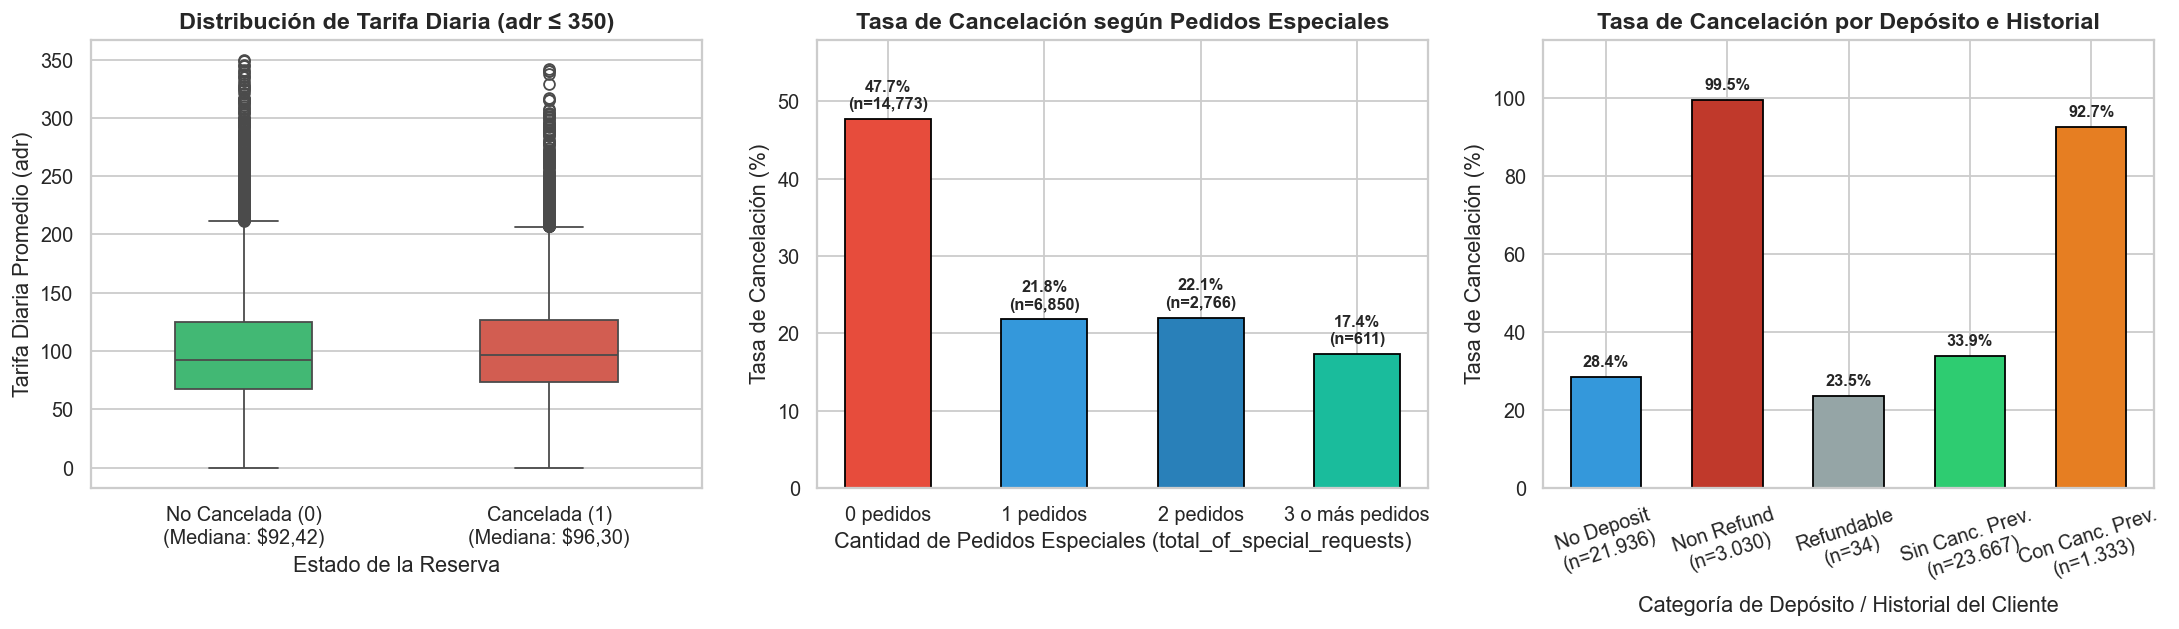

In [23]:
# Visualización Comparativa 3: ADR por cancelación, Pedidos Especiales y Tipo de Depósito / Historial
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Panel 1: Boxplot de ADR según is_canceled (acotado a adr <= 350 para visualización limpia de cuartiles)
sns.boxplot(
    data=df[df["adr"] <= 350],
    x="is_canceled",
    y="adr",
    hue="is_canceled",
    palette=["#2ecc71", "#e74c3c"],
    legend=False,
    width=0.45,
    ax=axes[0]
)
axes[0].set_title("Distribución de Tarifa Diaria (adr ≤ 350)")
axes[0].set_xlabel("Estado de la Reserva")
axes[0].set_ylabel("Tarifa Diaria Promedio (adr)")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["No Cancelada (0)\n(Mediana: $92,42)", "Cancelada (1)\n(Mediana: $96,30)"])

# Panel 2: Tasa de cancelación según cantidad de pedidos especiales
barras_req = axes[1].bar(
    comp_requests["pedidos_especiales"],
    comp_requests["tasa_cancelacion_pct"],
    color=["#e74c3c", "#3498db", "#2980b9", "#1abc9c"],
    edgecolor="black",
    width=0.55
)
axes[1].set_title("Tasa de Cancelación según Pedidos Especiales")
axes[1].set_xlabel("Cantidad de Pedidos Especiales (total_of_special_requests)")
axes[1].set_ylabel("Tasa de Cancelación (%)")
axes[1].set_ylim(0, 58)
for barra, n_val in zip(barras_req, comp_requests["total_reservas"]):
    h = barra.get_height()
    axes[1].annotate(
        f"{h:.1f}%\n(n={n_val:,})",
        xy=(barra.get_x() + barra.get_width() / 2, h),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center", va="bottom", fontsize=9, fontweight="bold"
    )

# Panel 3: Comparación por Tipo de Depósito e Historial Previo
etiquetas_comp = [
    "No Deposit\n(n=21.936)",
    "Non Refund\n(n=3.030)",
    "Refundable\n(n=34)",
    "Sin Canc. Prev.\n(n=23.667)",
    "Con Canc. Prev.\n(n=1.333)"
]
tasas_comp = [28.43, 99.54, 23.53, 33.91, 92.72]
colores_comp = ["#3498db", "#c0392b", "#95a5a6", "#2ecc71", "#e67e22"]

barras_c = axes[2].bar(etiquetas_comp, tasas_comp, color=colores_comp, edgecolor="black", width=0.58)
axes[2].set_title("Tasa de Cancelación por Depósito e Historial")
axes[2].set_xlabel("Categoría de Depósito / Historial del Cliente")
axes[2].set_ylabel("Tasa de Cancelación (%)")
axes[2].set_ylim(0, 115)
axes[2].tick_params(axis="x", rotation=18)
for barra in barras_c:
    h = barra.get_height()
    axes[2].annotate(
        f"{h:.1f}%",
        xy=(barra.get_x() + barra.get_width() / 2, h),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center", va="bottom", fontsize=9, fontweight="bold"
    )

plt.tight_layout()
plt.show()

### 4.3. Interpretación de la Pregunta Exploratoria 3

* **📊 Resultado observado (lo que muestran las consultas y los gráficos):**
  1. **Duración de la estadía (`total_stays_nights`):** Ambos grupos exhiben exactamente la **misma mediana (3,0 noches)** y el **mismo rango intercuartílico ($Q_1 = 2$, $Q_3 = 4$ noches)**, con medias casi idénticas (`3,40` noches en no canceladas vs. `3,48` noches en canceladas).
  2. **Tarifa diaria promedio (`adr`):** Las reservas canceladas registran una tarifa promedio levemente superior (**\$105,63**, $DE = 71,74$, mediana **\$96,30**) respecto de las no canceladas (**\$99,97**, $DE = 49,40$, mediana **\$92,42**). La mayor dispersión en el grupo cancelado se debe en parte al valor atípico extremo de `adr = 5400`.
  3. **Variables de compromiso e historial:**
     * **Pedidos especiales (`total_of_special_requests`):** Las reservas sin ningún pedido especial (`0 pedidos`, `n = 14.773`) tienen una tasa de cancelación del **47,74%**, mientras que aquellas con al menos `1 pedido especial` (`n = 6.850`) caen abruptamente al **21,80%**, y con `3 o más pedidos` (`n = 611`) descienden al **17,35%**.
     * **Antecedentes (`previous_cancellations`):** Los clientes con al menos una cancelación previa (`n = 1.333`) cancelan el **92,72%** de las veces, frente al **33,91%** de quienes no registran antecedentes (`n = 23.667`).
     * **Tipo de depósito (`deposit_type`):** Mientras que `No Deposit` (`n = 21.936`) tiene un **28,43%** de cancelación, la categoría **`Non Refund` (`n = 3.030`) alcanza un sorprendente 99,54% de cancelación** (`3.016` canceladas).
* **💡 Interpretación analítica (con prudencia metodológica):**
  * La duración total de la estadía por sí sola aporta escasa capacidad discriminante lineal entre ambos grupos, y el precio diario (`adr`) muestra una diferencia moderada (~\$3,88 en la mediana).
  * En cambio, el grado de involucramiento del huésped en la personalización de su estadía (`total_of_special_requests`: pedir cuna, piso alto, vista o cama específica) actúa como un fuerte indicador conductual de compromiso real con el viaje. Asimismo, el historial previo de cancelación (`previous_cancellations`) evidencia una alta persistencia de comportamiento.

---

## 5. Patrones Especiales y Casos Llamativos (Anomalías e Inconsistencias)

Siguiendo el criterio metodológico de **identificar anomalías y segmentos llamativos sin eliminarlos ni corregirlos automáticamente**, ejecutamos consultas SQL específicas para auditar los registros atípicos del dataset.

In [24]:
# Consulta SQL 4A: Cuantificación general de casos llamativos o inusuales en el dataset
anomalias_resumen = con.sql("""
SELECT
    SUM(CASE WHEN adr <= 0 THEN 1 ELSE 0 END) AS casos_adr_cero_o_negativo,
    SUM(CASE WHEN adr > 1000 THEN 1 ELSE 0 END) AS casos_adr_extremo_mayor_1000,
    SUM(CASE WHEN total_stays_nights = 0 THEN 1 ELSE 0 END) AS casos_estadia_0_noches,
    SUM(CASE WHEN total_guests = 0 THEN 1 ELSE 0 END) AS casos_sin_huespedes_0,
    SUM(CASE WHEN lead_time > 365 THEN 1 ELSE 0 END) AS casos_anticipacion_mayor_1_anio,
    SUM(CASE WHEN deposit_type = 'Non Refund' THEN 1 ELSE 0 END) AS casos_non_refund
FROM reservas
""").df()

anomalias_resumen

,casos_adr_cero_o_negativo,casos_adr_extremo_mayor_1000,casos_estadia_0_noches,casos_sin_huespedes_0,casos_anticipacion_mayor_1_anio,casos_non_refund
0,423.0,1.0,141.0,32.0,676.0,3030.0


In [25]:
# Consulta SQL 4B: Inspección puntual de los registros con valores extremos en ADR y estadías largas
casos_extremos = con.sql("""
SELECT
    booking_id, hotel, is_canceled, lead_time, adr,
    total_stays_nights, total_guests, market_segment, deposit_type
FROM reservas
WHERE adr > 450 OR total_stays_nights > 45 OR total_guests > 10
ORDER BY adr DESC, total_stays_nights DESC
LIMIT 10
""").df()

casos_extremos

,booking_id,hotel,is_canceled,lead_time,adr,total_stays_nights,total_guests,market_segment,deposit_type
0,HB-048516,City Hotel,1,35,5400.0,1,2,Offline TA/TO,Non Refund
1,HB-014038,Resort Hotel,0,113,110.5,60,1,Direct,No Deposit
2,HB-014039,Resort Hotel,0,126,110.0,69,1,Direct,No Deposit
3,HB-002419,Resort Hotel,1,334,0.0,7,20,Direct,No Deposit
4,HB-002165,Resort Hotel,1,361,0.0,7,26,Offline TA/TO,No Deposit
5,HB-001885,Resort Hotel,1,347,0.0,7,26,Offline TA/TO,No Deposit


### Análisis de los Patrones y Casos Llamativos Detectados:

1. **Caso extremo de tarifa diaria (`adr = 5.400,00` en `booking_id = 'HB-048516'`):**
   * Existe una única reserva en `City Hotel` (`Offline TA/TO`, `Non Refund`, `is_canceled = 1`) con `adr = 5400.0`, más de 10 veces superior al segundo valor más alto del dataset (`adr = 508.0` en `HB-015084`). Si bien distorsiona la media y el desvío estándar del grupo cancelado, **no se elimina en esta etapa**, dejando documentada la conveniencia de utilizar medianas o aplicar un filtro/winsorización antes del modelado predictivo.
2. **Reservas con tarifa `adr = 0` (`423` casos) y estadías de `0 noches` (`141` casos):**
   * Las 423 observaciones con `adr = 0` pueden corresponder a estadías bonificadas (`Complementary`), canjes de programas de fidelidad o errores de carga administrativa. Por su parte, las 141 reservas con `total_stays_nights = 0` suelen representar usos diurnos de habitación (*day-use*) o reservas dadas de baja el mismo día del *check-in*.
3. **Reservas con `total_guests = 0` (`32` casos con 0 adultos, 0 niños y 0 bebés):**
   * Constituyen una inconsistencia lógica de registro (una habitación reservada sin ocupantes declarados), posiblemente originada en bloqueos administrativos de habitaciones o errores de captura del sistema PMS del hotel.
4. **El patrón contraintuitivo de `deposit_type = 'Non Refund'` (`3.030` casos con 99,54% de cancelación):**
   * Intuitivamente, un depósito "no reembolsable" debería desalentar la cancelación; sin embargo, en este dataset presenta un **99,54% de cancelaciones** y un `lead_time` medio de **210,9 días**. En la literatura sobre este dataset hotelero (Antonio, de Almeida & Nunes, 2019), este fenómeno se explica porque muchas reservas de operadores y grupos con tarifas promocionales no reembolsables se cargan bajo esta etiqueta cuando entran en disputa de pago o cancelación masiva de cupos, o bien constituye una variable con potencial *fuga de información* (*data leakage*) si la marca se actualiza al momento de retener el depósito tras una cancelación.

---

## 6. Selección y Justificación de Variables Candidatas para Modelado Posterior

Con base en la evidencia empírica recolectada durante el Análisis Exploratorio de Datos, seleccionamos y justificamos las **variables candidatas** más relevantes para predecir `is_canceled` en las próximas etapas del TPI:

| Variable Candidata | Naturaleza | Nivel de Relevancia | Justificación Basada en la Evidencia del EDA |
|---|---|---|---|
| **`lead_time`** | Cuantitativa discreta | **Muy Alta** | Muestra una separación neta entre grupos (mediana de 112 días en canceladas vs. 45 días en no canceladas) y un incremento monotónico de la tasa de cancelación del 9,50% al 55,97%. |
| **`market_segment`** | Categórica nominal | **Muy Alta** | Discrimina fuertemente el riesgo según el canal comercial: desde el 15,41% en ventas directas (`Direct`) y 19,02% en `Corporate`, hasta el 36,51% en `Online TA` y 60,91% en `Groups`. |
| **`total_of_special_requests`** | Cuantitativa discreta | **Alta** | Captura el compromiso conductual del cliente: quienes realizan 1 o más pedidos especiales cancelan menos de la mitad (21,80% a 17,35%) que quienes no registran ninguno (47,74%). |
| **`previous_cancellations`** | Cuantitativa / Binaria | **Alta** | El historial previo de cancelación (`> 0`) se asocia con un 92,72% de reincidencia frente a 33,91% en clientes sin antecedentes. |
| **`hotel`** | Categórica binaria | **Alta** | El establecimiento urbano (`City Hotel`: 41,72%) presenta un riesgo basal significativamente mayor que el vacacional (`Resort Hotel`: 27,78%) e interactúa con el segmento comercial. |
| **`deposit_type`** | Categórica nominal | **Alta (con precaución)** | Posee altísima capacidad predictiva estadística (`Non Refund` = 99,54% cancelado vs. `No Deposit` = 28,43%), pero deberá evaluarse en el modelado con y sin esta variable para descartar posible *data leakage*. |
| **`adr`** | Cuantitativa continua | **Media** | Aporta información sobre el nivel tarifario (mediana de \$96,30 en canceladas vs. \$92,42 en no canceladas), especialmente útil en interacción con el mes de arribo y el tipo de hotel, previo tratamiento del outlier de \$5.400. |
| **`arrival_date_month`** y **`total_stays_nights`** | Temporal / Cuantitativa | **Media-Baja (Complementaria)** | Aunque `total_stays_nights` no difiere en mediana de forma aislada (3 noches en ambos grupos), combinada con la estacionalidad mensual (`arrival_date_month`) ayuda a caracterizar el perfil vacacional vs. corporativo. |

---

## 7. Conclusiones Exploratorias (Síntesis de Tres Hallazgos Principales)

1. **Hallazgo 1 — La anticipación (`lead_time`) es el principal factor cuantitativo asociado a la cancelación:**
   * *Qué muestran los datos:* Las reservas canceladas presentan una mediana de anticipación de **112 días** ($RIC = 164$) frente a **45 días** ($RIC = 116$) en las reservas efectivizadas. La proporción de cancelación se multiplica por casi seis veces entre las reservas realizadas dentro de la última semana (**9,50%**) y aquellas efectuadas con más de seis meses de antelación (**55,97%**).
   * *Interpretación:* Los horizontes de reserva extensos incrementan sustancialmente la incertidumbre del viaje y la probabilidad de anulación.

2. **Hallazgo 2 — Existe una brecha estructural según el tipo de hotel y el canal de comercialización (`hotel` y `market_segment`):**
   * *Qué muestran los datos:* El **`City Hotel`** registra un **41,72%** de cancelaciones frente al **27,78%** del **`Resort Hotel`**. Al desglosar por segmento comercial, los contingentes (**`Groups`**: **60,91%** general y **68,04%** en `City Hotel`) y las agencias online (**`Online TA`**: **36,51%**) concentran las mayores tasas de baja, mientras que la venta directa (**`Direct`**: **15,41%**) y corporativa (**`Corporate`**: **19,02%**) muestran alta estabilidad.
   * *Interpretación:* Las reservas intermediadas o asociadas a bloqueos grupales presentan menor fidelidad o mayor flexibilidad de cancelación que aquellas gestionadas directamente por el huésped o por cuenta empresarial.

3. **Hallazgo 3 — Las señales de compromiso e historial del huésped superan en poder discriminante al precio o duración aislados:**
   * *Qué muestran los datos:* Mientras que la duración de la estadía (`total_stays_nights`) comparte idéntica mediana (**3 noches**) en ambos grupos y la tarifa diaria (`adr`) exhibe una diferencia moderada en mediana (**\$96,30** vs. **\$92,42**), el registro de al menos un pedido especial (`total_of_special_requests >= 1`) reduce la tasa de cancelación del **47,74% al 21,80%**, y la presencia de cancelaciones previas (`previous_cancellations > 0`) eleva la tasa al **92,72%**.
   * *Interpretación:* Las acciones concretas de personalización del viaje y la conducta histórica del cliente ofrecen señales tempranas sumamente valiosas sobre la intención real de hospedarse.

---

## 8. Alcances y Limitaciones del Análisis

Antes de tomar decisiones operativas o avanzar hacia el entrenamiento de modelos predictivos, deben reconocerse al menos **tres limitaciones metodológicas fundamentales** de esta etapa exploratoria:

1. **Asociación estadística no equivale a causalidad (Presencia de variables confusoras):**
   * Las diferencias observadas en análisis bivariados pueden estar mediadas por terceras variables (*confounders*). Por ejemplo, la elevada tasa de cancelación del segmento `Groups` (60,91%) no se debe únicamente al canal en sí, sino también a que dicho segmento reserva con una anticipación promedio mucho mayor (`187,0` días) que el segmento `Direct` (`50,6` días). Todavía no se ha estimado el efecto neto de cada variable controlando simultáneamente por las demás.
2. **Posible sesgo operativo en `deposit_type` (*Non Refund*) y presencia de registros anómalos sin depurar:**
   * La tasa de cancelación del **99,54%** en reservas con depósito `Non Refund` requiere cautela antes de incluirla acríticamente en un modelo, ya que podría reflejar una convención contable o administrativa del sistema hotelero posterior al incumplimiento del cliente. Asimismo, existen registros inusuales (`1` caso con `adr = 5400`, `423` casos con `adr = 0` y `32` casos con `total_guests = 0`) que fueron conservados para diagnóstico exploratorio pero requerirán reglas de filtrado o imputación en la etapa de preprocesamiento para modelado.
3. **Variables no observadas en el dataset:**
   * El conjunto de datos no incluye factores externos como condiciones climáticas, eventos locales, precios de hoteles competidores ni la **antigüedad con la que se produjo la cancelación** respecto de la fecha de llegada (no es igual para el hotel una cancelación ocurrida 90 días antes del *check-in* que una ocurrida 24 horas antes).

In [26]:
# Cierre limpio de la conexión a DuckDB al finalizar el notebook
con.close()
print("🔒 Conexión a DuckDB cerrada correctamente. Notebook ejecutado de principio a fin sin errores.")

🔒 Conexión a DuckDB cerrada correctamente. Notebook ejecutado de principio a fin sin errores.
